In [77]:
import numpy as np
import matplotlib.pyplot as plt

from keras.datasets import boston_housing
from keras import models, layers

from sklearn.preprocessing import MinMaxScaler

# Zadatak 1

In [50]:
(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

In [51]:
print(train_data.shape, train_targets.shape, test_data.shape, test_targets.shape)

(404, 13) (404,) (102, 13) (102,)


In [52]:
min_values = np.min(train_data, axis=0)
max_values = np.max(train_data, axis=0)

print("atribut |    min |    max ")
for i in range(train_data.shape[1]):
    print(f"{(i + 1):7} | {min_values[i]:6.2f} | {max_values[i]:6.2f}")

atribut |    min |    max 
      1 |   0.01 |  88.98
      2 |   0.00 | 100.00
      3 |   0.46 |  27.74
      4 |   0.00 |   1.00
      5 |   0.39 |   0.87
      6 |   3.56 |   8.72
      7 |   2.90 | 100.00
      8 |   1.13 |  10.71
      9 |   1.00 |  24.00
     10 | 188.00 | 711.00
     11 |  12.60 |  22.00
     12 |   0.32 | 396.90
     13 |   1.73 |  37.97


In [48]:
print(f"Target: min = {np.min(train_targets):.2f}, max = {np.max(train_targets):.2f}")

Target: min = 5.00, max = 50.00


In [55]:
scaler = MinMaxScaler().fit(train_data)

train_data = scaler.transform(train_data)
test_data = scaler.transform(test_data)

In [58]:
def model_mreze(shape):
    model = models.Sequential()

    model.add(layers.Input(shape=shape))
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dense(1))

    return model

In [71]:
model = model_mreze((train_data.shape[1],))

In [72]:
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [73]:
history = model.fit(train_data, train_targets, epochs=100, batch_size=1, validation_split=0.1)

Epoch 1/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 390.7361 - mae: 16.3581 - val_loss: 33.3466 - val_mae: 4.6827
Epoch 2/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 57.2397 - mae: 5.4214 - val_loss: 20.2290 - val_mae: 3.4596
Epoch 3/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 43.0203 - mae: 4.3961 - val_loss: 23.1804 - val_mae: 3.6910
Epoch 4/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 36.1489 - mae: 4.2498 - val_loss: 20.4707 - val_mae: 3.3643
Epoch 5/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 32.7303 - mae: 3.8737 - val_loss: 21.0845 - val_mae: 3.2619
Epoch 6/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 22.3595 - mae: 3.4223 - val_loss: 20.8607 - val_mae: 3.3328
Epoch 7/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 24.8574 - mae: 3.4547 - val_loss: 22.0939 - val_mae: 3.4718
Epoch 8/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 20.3741 - mae: 3.2041 - val_loss: 20.3205 - val_mae: 3.2553
Epoch 9/100
363/363 ━━━━━━━━━━

In [87]:
print("Krajnja vrijednost funkcije gubitka:", history.history["loss"][-1])
print("Krajnja vrijednost metrike MAE:", history.history["mae"][-1])

Krajnja vrijednost funkcije gubitka: 6.41891622543335
Krajnja vrijednost metrike MAE: 1.8145359754562378


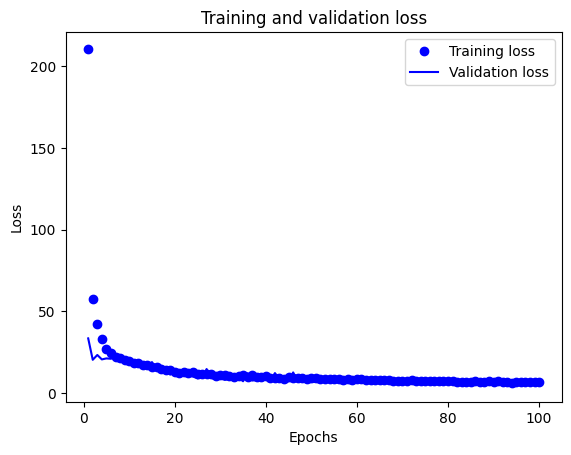

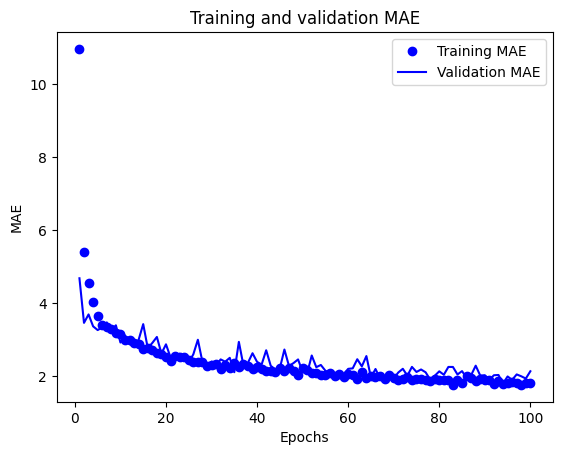

In [88]:
epochs = range(1, 101)

loss_values = history.history["loss"]
val_loss_values = history.history["val_loss"]

plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.clf()

mae_values = history.history["mae"]
val_mae_values = history.history["val_mae"]

plt.plot(epochs, mae_values, "bo", label="Training MAE")
plt.plot(epochs, val_mae_values, "b", label="Validation MAE")
plt.title("Training and validation MAE")
plt.xlabel("Epochs")
plt.ylabel("MAE")
plt.legend()
plt.show()

In [91]:
def smooth_curve(points, factor=0.9):
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(previous * factor + point * (1 - factor))
        else:
            smoothed_points.append(point)
    return smoothed_points

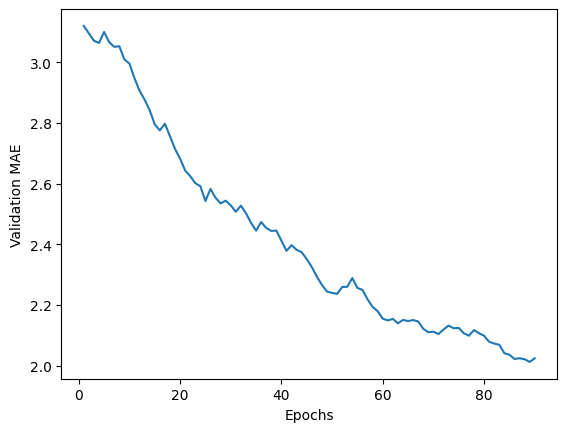

In [92]:
val_mae = history.history["val_mae"]
smooth_val_mae = smooth_curve(val_mae[10:])

plt.plot(range(1, len(smooth_val_mae) + 1), smooth_val_mae)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [93]:
model = model_mreze((train_data.shape[1],))

In [94]:
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [95]:
history = model.fit(train_data, train_targets, epochs=500, batch_size=1, validation_split=0.1)

Epoch 1/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 351.4968 - mae: 15.2883 - val_loss: 26.6169 - val_mae: 4.1545
Epoch 2/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 72.0419 - mae: 6.0405 - val_loss: 23.7040 - val_mae: 3.9021
Epoch 3/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 40.4338 - mae: 4.5467 - val_loss: 18.2598 - val_mae: 3.2849
Epoch 4/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 30.1911 - mae: 3.9062 - val_loss: 18.6399 - val_mae: 3.2021
Epoch 5/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 27.8125 - mae: 3.6667 - val_loss: 18.2802 - val_mae: 3.0557
Epoch 6/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 21.1391 - mae: 3.0801 - val_loss: 21.4944 - val_mae: 3.3038
Epoch 7/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 32.7863 - mae: 3.7653 - val_loss: 19.6892 - val_mae: 3.1477
Epoch 8/500
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 17.0240 - mae: 2.8975 - val_loss: 17.7161 - val_mae: 3.1440
Epoch 9/500
363/363 ━━━━━━━━━━

In [96]:
print("Krajnja vrijednost funkcije gubitka:", history.history["loss"][-1])
print("Krajnja vrijednost metrike MAE:", history.history["mae"][-1])

Krajnja vrijednost funkcije gubitka: 1.6319915056228638
Krajnja vrijednost metrike MAE: 0.9639671444892883


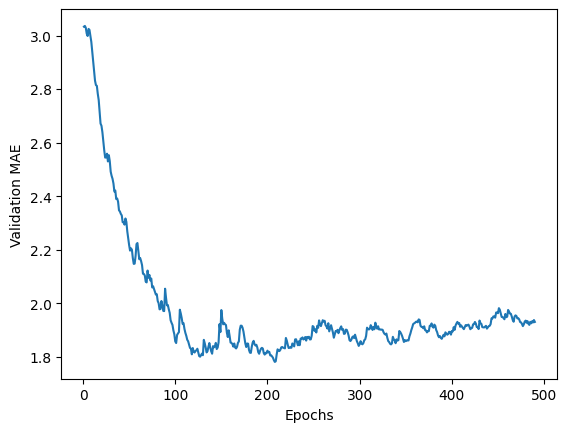

In [97]:
val_mae = history.history["val_mae"]
smooth_val_mae = smooth_curve(val_mae[10:])

plt.plot(range(1, len(smooth_val_mae) + 1), smooth_val_mae)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [98]:
test_loss, test_mae = model.evaluate(test_data, test_targets)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - loss: 9.9580 - mae: 2.0809
